## Анализ данных о Нобелевских лауреатах

### **Контекст проекта**
В этом задании мы будем работать с датасетом о лауреатах Нобелевской премии. Я обработал данные, провел первичный анализ данных, изучил распределение по странам, статистику многократных лауреатов и случаев отказов от премии.



## Импорт библиотек

Подключим необходимые библиотеки и собственные модули для обработки, фильтрации, группировки и анализа данных.  
json, requests, matplotlib - стандартные питоновские библиотеки.  
Отдельные функции вынесены в отдельные файлы, которые мы будем использовать в процессе исследования

In [169]:
import json
import requests
import matplotlib.pyplot as plt

from json_dict_processing import (
    extract_nested_value,
    process_dictionary_with_config,
    process_list_of_dicts_with_config,
    create_processor
)

from laureates_configs import (
    CONFIG_PERSON,
    CONFIG_ORG,
    process_person,
    process_org
)

from prizes_configs import CONFIG_PRIZE, process_prizes

from dataset_helpers import (
    filter_cond,
    group_by,
    aggregate_groups
)

from aggregations import (
    calc_mean,
    calc_top_n
)

from atribute_manager import add_attribute

## Загрузка данных

Получим данные о Нобелевских лауреатах через API. Если запрос завершится ошибкой, загрузим данные из локального json файла.

In [170]:
URL_LAUREATES = 'https://api.nobelprize.org/2.1/laureates?limit=1200'

try:
    response = requests.get(URL_LAUREATES, timeout=30)
    response.raise_for_status()
    data = response.json()
    print('Данные успешно загружены из API')
except:
    print('Ошибка получения данных по API, загрузка из файла')
    with open('laureates.json', 'r', encoding='utf-8') as file:
        data = json.load(file)
    if (len(data) > 0):
        print('Данные успешно загружены из файла')
    else:
        print('Не удалось загрузить данные')


Ошибка получения данных по API, загрузка из файла
Данные успешно загружены из файла


## Обработка данных

Преобразуем исходные данные в удобный для анализа формат. Определим тип каждого лауреата (человек или организация) и обработаем его с помощью соответствующей конфигурации.  
Для различия людей и организаций добавим атрибут type со значениями person/org.

In [171]:
def get_laureate_data(laureate):

    if 'knownName' in laureate:
        result = process_person(laureate)
        result['type'] = 'person'
    elif 'orgName' in laureate:
        result = process_org(laureate)
        result['type'] = 'org'

    return result


laureates_data = []

for laureate in data['laureates']:
    laureates_data.append(get_laureate_data(laureate))

## Этап 2. Первичный анализ данных (EDA)

В рамках EDA ответим на следующие вопросы:

1. **Сколько всего записей?** Определим общее количество лауреатов, а также отдельно посчитаем людей и организации.
2. **Все ли значения полей заполнены?** Проверим наличие пропущенных данных.
3. **Сколько пропусков в каждом из полей и какова их доля?** Подсчитаем количество отсутствующих значений по каждому атрибуту и их процент от общего числа записей.
4. **Каковы максимальное и минимальное значения поля ID и каким годам награждения они соответствуют?** Также проверим наличие повторяющихся идентификаторов и разрывов больше единицы между соседними ID в отсортированном списке.

Для анализа используются данные лауреатов согласно конфигу. Пропуски у людей и организаций рассматриваются отдельно, потому что их наборы атрибутов различаются.

In [172]:
# Определяем количество всех записей, а также отдельно записей для людей и организаций
print(f'Всего записей: {len(laureates_data)}')

persons = [x for x in laureates_data if x['type'] == 'person']
organizations = [x for x in laureates_data if x['type'] == 'org']
print(f'Людей: {len(persons)}')
print(f'Организаций: {len(organizations)}')


Всего записей: 1028
Людей: 1000
Организаций: 28


In [173]:
def count_missing(records):
    result = {}

    for field in records[0]:
        result[field] = sum(1 for record in records 
                            if record.get(field) is None)
    return result


# Определяем количество пропусков и их долю среди общего числа записей среди людей и организаций
person_missing = count_missing(persons)
org_missing = count_missing(organizations)

print('\nПропуски в полях людей-лауреатов:')
for field, count in person_missing.items():
    percentage = count / len(persons) * 100
    print(f'{field}: {count} ({percentage:.2f}%)')

print('\nПропуски в полях организаций-лауреатов:')
for field, count in org_missing.items():
    percentage = count / len(organizations) * 100
    print(f'{field}: {count} ({percentage:.2f}%)')


Пропуски в полях людей-лауреатов:
id: 0 (0.00%)
name: 0 (0.00%)
gender: 0 (0.00%)
birth_year: 0 (0.00%)
country_birth: 3 (0.30%)
country_now: 3 (0.30%)
prizes_relevant: 0 (0.00%)
type: 0 (0.00%)

Пропуски в полях организаций-лауреатов:
id: 0 (0.00%)
name: 0 (0.00%)
founded_year: 1 (3.57%)
country_founded: 4 (14.29%)
country_now: 4 (14.29%)
prizes_relevant: 0 (0.00%)
type: 0 (0.00%)


In [174]:
def get_award_years(laureate):
    years = []

    for prize in laureate['prizes_relevant']:
        years.append(prize['award_year'])

    return years


# Отсортируем лауретов по айдишникам, найдем минимальный имаксимальный
sorted_laureates = sorted(laureates_data,
                          key=lambda laureate: int(laureate['id']))
min_laureate = sorted_laureates[0]
max_laureate = sorted_laureates[-1]
print(f'\nМинимальный ID: {min_laureate['id']}')
print(f'Максимальный ID: {max_laureate['id']}')

print( f'Годы награждения минимального ID: {get_award_years(min_laureate)}')
print(f'Годы награждения максимального ID: {get_award_years(max_laureate)}')

# Проверим наличие дубликатов и пропусков
ids = [int(laureate['id']) for laureate in laureates_data]
set_ids = set(ids)
if len(ids) != len(set_ids):
    print('\nЕсть повторяющиеся ID')
    print(f'Их: {len(ids) - len(set_ids)}')
else:
    print('\nНет повторяющихся ID')

ids.sort()
gaps = []
for i in range(1, len(ids)):
    if ids[i] - ids[i-1] > 1:
        gaps.append((ids[i-1], ids[i]))

print(f'Разрывы между ID: {gaps}')


Минимальный ID: 1
Максимальный ID: 1070
Годы награждения минимального ID: [1901]
Годы награждения максимального ID: [2026]

Нет повторяющихся ID
Разрывы между ID: [(6, 8), (93, 95), (169, 172), (255, 257), (468, 470), (503, 505), (520, 523), (541, 543), (569, 571), (590, 592), (594, 596), (597, 600), (610, 613), (615, 617), (631, 633), (635, 637), (645, 647), (655, 657), (783, 786), (787, 789), (858, 861), (896, 903), (949, 958), (1009, 1011)]


### Вспомогательные модули для анализа данных

Для удобства работы с данными были созданы 3 файла с функциями:

- **`dataset_helpers.py`** - фильтрация записей по условиям, группировка по атрибутам и применение агрегирующих функций.
- **`aggregations.py`** - расчёт среднего и получение топ N записей.
- **`attribute_manager.py`** - добавление новых атрибутов.


----------

### 2.1. Топ-статистика по странам

Рассмотрим распределение Нобелевских лауреатов по странам.

- Определим **топ-5 стран** по общему количеству лауреатов.
- Построим аналогичные рейтинги отдельно для каждой категории премий.

Для анализа используем страну рождения человека или страну основания организации. Записи с неизвестной страной исключим из подсчётов.

Топ 5 стран по количеству лауреатов
USA: 306
United Kingdom: 96
Germany: 82
France: 63
Japan: 32


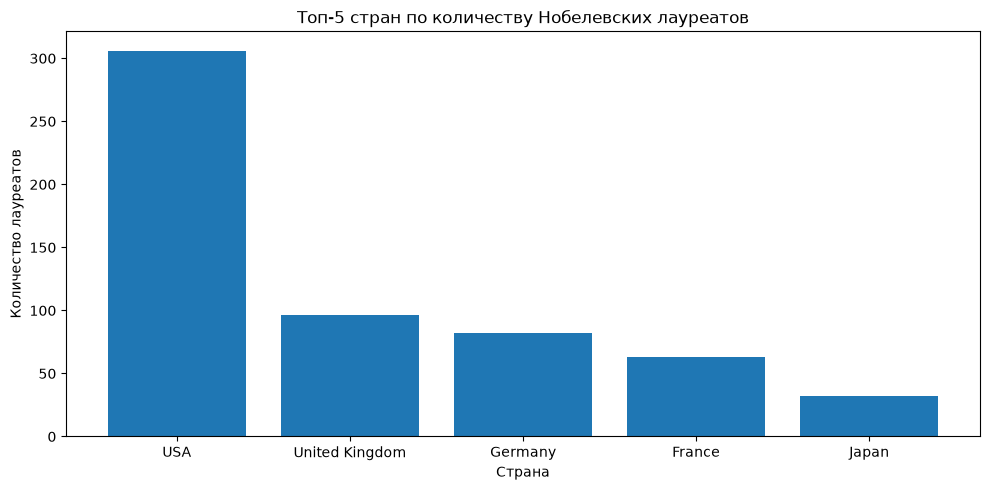

In [175]:
add_attribute(
    laureates_data,
    "country",
    lambda laureate: (
        laureate["country_birth"]
        if laureate["type"] == "person"
        else laureate["country_founded"]
    )
)

valid_laureates = filter_cond(
    laureates_data,
    "country",
    lambda country: country is not None
)

country_groups = group_by(valid_laureates, ["country"])
country_counts = aggregate_groups(country_groups, len)

country_results = []

for group_key, count in country_counts.items():
    country_results.append({
        "country": group_key[0],
        "count": count
    })

top_countries = calc_top_n(country_results, "count", 5)

print("Топ 5 стран по количеству лауреатов")
for record in top_countries:
    print(f"{record['country']}: {record['count']}")

plt.figure(figsize=(10, 5))
plt.bar(
    [record["country"] for record in top_countries],
    [record["count"] for record in top_countries])
plt.title("Топ-5 стран по количеству Нобелевских лауреатов")
plt.xlabel("Страна")
plt.ylabel("Количество лауреатов")
plt.tight_layout()
plt.show()

ТОП-5 СТРАН ПО КОЛИЧЕСТВУ ЛАУРЕАТОВ
USA: 306
United Kingdom: 96
Germany: 82
France: 63
Japan: 32


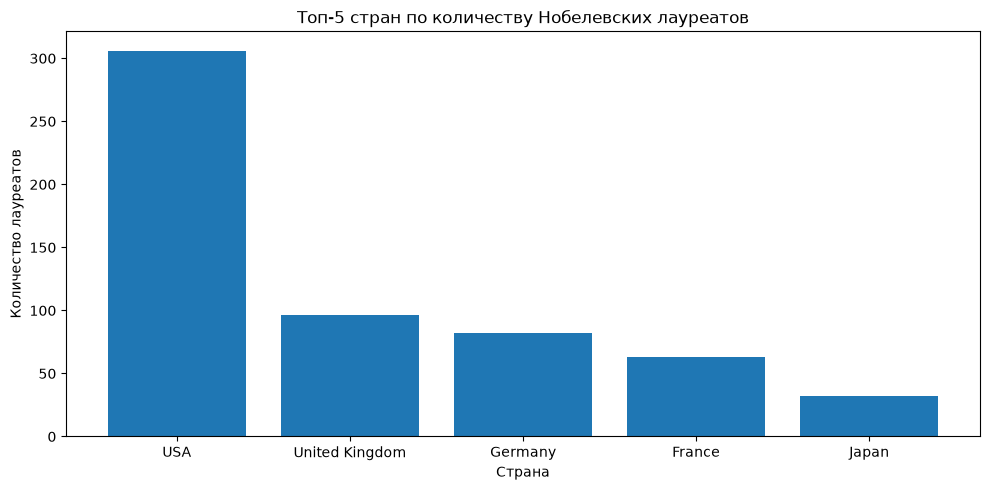

In [176]:
add_attribute(laureates_data, "country",
    lambda laureate: (laureate["country_birth"]
    if laureate["type"] == "person"
    else laureate["country_founded"]))

valid_laureates = filter_cond(laureates_data, "country",
    lambda country: country is not None)

country_groups = group_by(valid_laureates, ["country"])
country_counts = aggregate_groups(country_groups, len)

country_results = []

for group_key, count in country_counts.items():
    country_results.append({
        "country": group_key[0],
        "count": count
    })

top_countries = calc_top_n(country_results, "count", 5)

print("ТОП-5 СТРАН ПО КОЛИЧЕСТВУ ЛАУРЕАТОВ")

for record in top_countries:
    print(f"{record['country']}: {record['count']}")

plt.figure(figsize=(10, 5))
plt.bar(
    [record["country"] for record in top_countries],
    [record["count"] for record in top_countries]
)
plt.title("Топ-5 стран по количеству Нобелевских лауреатов")
plt.xlabel("Страна")
plt.ylabel("Количество лауреатов")
plt.tight_layout()
plt.show()

In [177]:
country_categories = []

for laureate in valid_laureates:
    categories = set()

    for prize in laureate["prizes_relevant"]:
        if prize["category_en"] is not None:
            categories.add(prize["category_en"])

    for category in categories:
        country_categories.append({
            "country": laureate["country"],
            "category": category
        })

category_groups = group_by(
    country_categories,
    ["category", "country"]
)

category_counts = aggregate_groups(category_groups, len)

category_results = []

for group_key, count in category_counts.items():
    category, country = group_key

    category_results.append({
        "category": category,
        "country": country,
        "count": count
    })

categories = sorted(set(
    record["category"] for record in category_results
))

print("\nТоп 5 стран по категориям")

for category in categories:
    filtered = filter_cond(category_results, "category",
                           lambda value: value == category)

    top_category_countries = calc_top_n(filtered, "count", 5)

    print(f"\n{category}")
    for record in top_category_countries:
        print(f"{record['country']}: {record['count']}")


Топ 5 стран по категориям

Chemistry
USA: 59
United Kingdom: 26
Germany: 24
France: 12
Japan: 9

Economic Sciences
USA: 56
United Kingdom: 7
Canada: 5
France: 5
the Netherlands: 4

Literature
France: 12
USA: 10
Sweden: 7
United Kingdom: 6
Spain: 5

Peace
USA: 26
France: 11
Switzerland: 8
United Kingdom: 7
Germany: 6

Physics
USA: 71
United Kingdom: 25
Germany: 24
Japan: 12
France: 11

Physiology or Medicine
USA: 85
United Kingdom: 25
Germany: 22
France: 12
Sweden: 8


### Выводы

По результатам анализа **лидируют США - 306 лауреатов**, что значительно больше, чем у остальных стран. Далее идут Великобритания (96), Германия (82), Франция (63) и Япония (32).

- **США** занимают первое место в пяти из шести категорий, везде, кроме литературы, где лидер - Франия.
- **Великобритания** и **Франиция** входят в топ-5 всех научных категорий.


### 2.2. Многократные лауреаты

Здесь мы ищем лауреатов, получивших Нобелевскую премию более одного раза.

- Найдём лауреатов с несколькими премиями и выясним, кто получил более двух наград.
- Проверим, совпадают ли категории первой и второй премий.
- Рассчитаем среднее время между первым и вторым награждением.


In [178]:
multiple_laureates = filter_cond(laureates_data, "prizes_relevant",
                                 lambda prizes: prizes is not None
                                 and len(prizes) > 1)

more_than_two = filter_cond(multiple_laureates, "prizes_relevant",
                            lambda prizes: len(prizes) > 2)

print(f"Лауреатов с несколькими премиями: {len(multiple_laureates)}")
print(f"Лауреатов с более чем двумя премиями: {len(more_than_two)}")
same_category = 0
different_category = 0
time_between = []

Лауреатов с несколькими премиями: 7
Лауреатов с более чем двумя премиями: 1


In [179]:
print("\nЛауреаты с одной и более премиями:")
for laureate in multiple_laureates:
    prizes = []

    for prize in laureate["prizes_relevant"]:
        prizes.append(f"{prize['category_en']} ({prize['award_year']})")

    print(f"{laureate['name']}: {', '.join(prizes)}")

print("\nЛауреаты с двумя и более премиями:")
for laureate in more_than_two:
    prizes = []

    for prize in laureate["prizes_relevant"]:
        prizes.append(f"{prize['category_en']} ({prize['award_year']})")

    print(f"{laureate['name']}: {', '.join(prizes)}")


Лауреаты с одной и более премиями:
Frederick Sanger: Chemistry (1958), Chemistry (1980)
International Committee of the Red Cross: Peace (1917), Peace (1944), Peace (1963)
John Bardeen: Physics (1956), Physics (1972)
K. Barry Sharpless: Chemistry (2001), Chemistry (2022)
Linus Pauling: Chemistry (1954), Peace (1962)
Marie Curie: Physics (1903), Chemistry (1911)
Office of the United Nations High Commissioner for Refugees: Peace (1954), Peace (1981)

Лауреаты с двумя и более премиями:
International Committee of the Red Cross: Peace (1917), Peace (1944), Peace (1963)


In [180]:
for laureate in multiple_laureates:
    prizes = sorted(laureate["prizes_relevant"],
                    key=lambda prize: prize["award_year"])
    first_prize = prizes[0]
    second_prize = prizes[1]

    if first_prize["category_en"] == second_prize["category_en"]:
        same_category += 1
    else:
        different_category += 1

    interval = second_prize["award_year"] - first_prize["award_year"]
    time_between.append({
        "name": laureate["name"],
        "interval": interval
    })

print("\nУ скольких людей совпадает категории первой и второй премии:")
print(f"Совпадают: {same_category}")
print(f"Не совпадают: {different_category}")


print(f"\nСреднее время между первой и второй премией {calc_mean(time_between, 'interval'):.2f} лет")


У скольких людей совпадает категории первой и второй премии:
Совпадают: 5
Не совпадают: 2

Среднее время между первой и второй премией 18.43 лет


### Выводы

В результате анализа было обнаружено **7 лауреатов**, получивших Нобелевскую премию более одного раза.

- Только **один лауреат** получил более двух премий - International Committee of the Red Cross (1917, 1944 и 1963 годы).
- У **5 лауреатов** категории первой и второй премий совпадают, у **2 лауреатов** - различаются.
- **Средний промежуток** между первым и вторым награждением составляет **18,43 года**.


### 2.3. Отказы от Нобелевских премий

Найдем случаи отказа от Нобелевских премий.

- Определим, в каких категориях чаще всего отказывались от премий.
- Проверим, встречались ли отказы среди организаций-лауреатов.

Сначала сделали список всех лауретов с отказами по атрибуту _prize_status_ со значением _declined_, потом разделили их на людей и организации.  
Далее сгруппировали по категориям и отсортировали по количеству отказов в каждой категории по убыванию.

In [181]:
declined_prizes = []
org_decline = []

for laureate in laureates_data:
    for prize in laureate["prizes_relevant"]:
        if prize["prize_status"] == "declined":
            declined_prizes.append(prize)

            if laureate["type"] == "org":
                org_decline.append(prize)

print("Всего отказов:", len(declined_prizes))
print("Отказов среди организаций:", len(org_decline))

Всего отказов: 2
Отказов среди организаций: 0


In [ ]:
category_groups = group_by(declined_prizes, ["category_en"])
category_counts = aggregate_groups(category_groups, len)

sorted_categories = sorted(category_counts.items(),
                           key=lambda value: value[1], reverse=True)

print("\nОтказы по категориям (отсортировано по убыванию):")
for category, count in sorted_categories:
    print(f"{category[0]}: {count}")


Отказы по категориям (отсортировано по убыванию):
Literature: 1
Peace: 1


### Выводы
В результате найдено только 2 отказа от премии:
- Литература
- Премия мира  
  
Среди организаций никто не отказывался от премии.

## Общие выводы

В ходе работы были обработаны и проанализированы данные о **1028 Нобелевских лауреатах**.

По результатам исследования можно выделить несколько основных выводов:

- **США лидируют** по количеству лауреатов — 306 человек и организаций, занимая первое место в пяти из шести категорий премий.
- **Повторное награждение встречается редко:** только 7 лауреатов получили более одной премии, а более двух премий получил лишь International Committee of the Red Cross.
- **Отказываются от премий редко:** обнаружено всего 2 случая — в литературе и премии мира. Среди организаций отказов не найдено.